# Chapitre 14 - Cours 1 : règles d'association et apprentissage non supervisé vu comme supervisé

Ce premier notebook du chapitre 14 couvre les sections 14.1 et 14.2 du livre :

1. ce qui distingue l'apprentissage **non supervisé** de l'apprentissage supervisé ;
2. les **règles d'association** (« analyse du panier de la ménagère ») et l'algorithme **Apriori**,
   appliqués aux données démographiques `marketing` (figure 14.2 du livre) ;
3. l'astuce qui transforme l'**estimation d'une densité** en un problème de **classification**
   supervisée (section 14.2.4, figure 14.3) ;
4. les **règles d'association généralisées** obtenues avec PRIM (sections 14.2.5 à 14.2.7).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from esl.plotting import set_style, COLORS, BLUE, ORANGE, GRAY, SEQ, DIV, TWO_CLASS
from esl import datasets
from esl import ch14_non_supervise as ns
set_style()

## 1. Apprentissage supervisé et non supervisé

En apprentissage **supervisé**, on dispose de couples $(x_i, y_i)$ et l'on cherche à prédire
$Y$ à partir de $X$. Le « professeur » (la réponse $y_i$) permet de mesurer la qualité d'une
prédiction, par exemple par la perte quadratique. Formellement, on cherche en chaque $x$ la
valeur

$$\mu(x) = \operatorname*{argmin}_{\theta} \; \mathbb{E}_{Y\mid X=x}\, L(Y, \theta),$$

ce qui est l'éq. (14.1) du livre : on n'étudie que la **loi conditionnelle** de $Y$ sachant $X$.

En apprentissage **non supervisé**, on observe seulement $x_1, \dots, x_N$, réalisations
indépendantes d'un vecteur aléatoire $X \in \mathbb{R}^p$ de densité $g$. Le but est de
**décrire** $g$ : où se concentre la masse de probabilité (modes, régions de forte densité),
quelles variables sont liées entre elles, existe-t-il des groupes naturels, des structures de
faible dimension ?

> **Intuition.** Il n'y a pas de « bonne réponse » à laquelle se comparer : aucune mesure
> d'erreur directe comme l'erreur de test. La validité d'une analyse non supervisée relève
> souvent du jugement de l'utilisateur, ce qui explique la profusion de méthodes heuristiques.

Quand $p$ est petit (1, 2 ou 3), on peut estimer $g$ directement (estimateurs à noyau du
chapitre 6). En grande dimension, c'est hors de portée (fléau de la dimension) et l'on se
contente de résumés :

* des **régions de forte densité** décrites par des conjonctions de conditions simples
  (règles d'association, ce notebook) ;
* des **groupes** d'observations (classification, cours 2) ;
* des **variétés de petite dimension** autour desquelles se concentrent les données
  (ACP, courbes principales, cartes auto-organisatrices, MDS… cours 3).

## 2. Règles d'association

### 2.1 Le problème : trouver des valeurs conjointes fréquentes

On considère $p$ variables **discrètes** $X_1, \dots, X_p$, typiquement des indicatrices
d'achat ($X_j = 1$ si le produit $j$ est dans le panier). Idéalement, on voudrait trouver des
valeurs « prototypes » $v_1, \dots, v_L$ de forte probabilité $\Pr(X = v_l)$. Mais avec beaucoup
de variables, chaque valeur conjointe a une probabilité minuscule : on relâche le problème.

Au lieu d'une valeur exacte, on cherche des sous-ensembles $s_j$ de valeurs pour certaines
variables $j \in \mathcal{J} \subset \{1, \dots, p\}$ tels que

$$\Pr\Big(\bigcap_{j \in \mathcal{J}} \{X_j \in s_j\}\Big) \quad \text{soit grande},$$

c'est l'éq. (14.2) du livre. Une telle conjonction s'appelle une **règle conjonctive** ;
elle décrit un « pavé » de l'espace des variables où la densité est élevée.

### 2.2 Codage en items et support

L'analyse du panier simplifie encore : chaque $s_j$ est soit une **seule** valeur, soit
l'ensemble de toutes les valeurs (la variable n'intervient pas). On code alors chaque couple
(variable, valeur) par une **indicatrice** $Z_k$ ; si la variable $j$ prend $|\mathcal{S}_j|$
valeurs, on obtient $K = \sum_j |\mathcal{S}_j|$ indicatrices appelées **items**.

Le problème devient : trouver des ensembles d'items $\mathcal{K} \subset \{1, \dots, K\}$
(des « paniers ») tels que

$$T(\mathcal{K}) = \frac{1}{N} \sum_{i=1}^N \prod_{k \in \mathcal{K}} z_{ik}$$

soit grand (éq. (14.5) du livre, version empirique de (14.4)). $T(\mathcal{K})$ est le
**support** (ou prévalence) de l'ensemble d'items : la proportion d'observations qui
possèdent **tous** les items de $\mathcal{K}$.

On fixe un seuil $t$ et l'on veut **tous** les ensembles d'items fréquents

$$\{\mathcal{K}_l \;\mid\; T(\mathcal{K}_l) > t\} \qquad \text{(éq. (14.6) du livre).}$$

Il y a $2^K$ ensembles possibles : avec $K = 50$, c'est environ $10^{15}$, impossible à
énumérer. L'algorithme **Apriori** exploite une propriété simple pour n'examiner qu'une
infime partie de ces ensembles.

### 2.3 L'algorithme Apriori

**Propriété (anti-monotonie du support).** Si $\mathcal{K} \subset \mathcal{K}'$ alors
$T(\mathcal{K}') \le T(\mathcal{K})$.

*Preuve.* Pour chaque observation, $\prod_{k \in \mathcal{K}'} z_{ik} = \prod_{k \in
\mathcal{K}} z_{ik} \cdot \prod_{k \in \mathcal{K}' \setminus \mathcal{K}} z_{ik}$, et le
second facteur vaut 0 ou 1, donc $\prod_{k \in \mathcal{K}'} z_{ik} \le \prod_{k \in
\mathcal{K}} z_{ik}$. On somme sur $i$ et on divise par $N$. $\square$

Conséquence : un ensemble de taille $m$ ne peut être fréquent que si **tous** ses
sous-ensembles de taille $m-1$ le sont. Apriori procède donc par niveaux :

1. calculer le support de chaque item seul et garder ceux qui dépassent $t$ ;
2. au passage $m$, former les candidats de taille $m$ en joignant deux ensembles fréquents de
   taille $m-1$ ayant les mêmes $m-2$ premiers items, éliminer les candidats dont un
   sous-ensemble de taille $m-1$ n'est pas fréquent, puis calculer le support des survivants
   (un seul passage sur les données) ;
3. s'arrêter quand plus aucun candidat n'est fréquent.

Notre implémentation est `ns.apriori` ; pour accélérer, chaque ensemble fréquent garde en
mémoire le vecteur booléen des observations qui le contiennent.

Commençons par un petit exemple « jouet » de 10 paniers et 5 produits.

In [2]:
produits = ["pain", "lait", "beurre", "café", "confiture"]
paniers = np.array([
    [1, 1, 1, 0, 0],
    [1, 1, 0, 1, 0],
    [1, 0, 1, 0, 1],
    [1, 1, 1, 0, 1],
    [0, 1, 0, 1, 0],
    [1, 1, 1, 1, 0],
    [1, 0, 1, 0, 1],
    [0, 1, 0, 1, 0],
    [1, 1, 1, 0, 0],
    [1, 0, 0, 0, 1],
], dtype=bool)
freq_jouet = ns.apriori(paniers, support_min=0.3)
pd.DataFrame([(", ".join(produits[k] for k in K), s) for K, s in freq_jouet.items()],
             columns=["ensemble d'items", "support"])

,ensemble d'items,support
0,pain,0.8
1,lait,0.7
2,beurre,0.6
3,café,0.4
4,confiture,0.4
5,"pain, lait",0.5
6,"pain, beurre",0.6
7,"pain, confiture",0.4
8,"lait, beurre",0.4
9,"lait, café",0.4


On vérifie l'anti-monotonie : par exemple {pain, beurre} a un support de 0,6, et
{pain, beurre, lait} un support de 0,4, plus petit. L'ensemble {café, confiture} n'apparaît
jamais : il n'a même pas été évalué au niveau 3.

### 2.4 Règles d'association : support, confiance, lift

Chaque ensemble fréquent $\mathcal{K}$ est découpé en deux parties disjointes
$\mathcal{K} = A \cup B$, ce qui donne une **règle** $A \Rightarrow B$ (éq. (14.7)) :
$A$ est l'**antécédent**, $B$ le **conséquent**. On lui associe :

* le **support** $T(A \Rightarrow B) = T(\mathcal{K})$, estimation de $\Pr(A \cap B)$ ;
* la **confiance** $C(A \Rightarrow B) = \dfrac{T(A \Rightarrow B)}{T(A)}$ (éq. (14.8)),
  estimation de $\Pr(B \mid A)$ ;
* le **lift** $L(A \Rightarrow B) = \dfrac{C(A \Rightarrow B)}{T(B)}$, estimation de
  $\dfrac{\Pr(A \cap B)}{\Pr(A)\Pr(B)}$.

> **Intuition.** La confiance dit « quand $A$ est présent, $B$ l'est aussi dans telle
> proportion des cas ». Le lift compare cette proportion à la fréquence globale de $B$ : un lift
> de 1 signifie que $A$ et $B$ sont (empiriquement) **indépendants** ; un lift de 2 que la
> présence de $A$ double la probabilité de $B$.

On ne garde que les règles de confiance supérieure à un seuil $c$ (éq. (14.9)).

In [3]:
regles_jouet = ns.regles_association(freq_jouet, confiance_min=0.7, noms=produits)
regles_jouet.sort_values("confiance", ascending=False).round(3)

,antecedent,consequent,taille,support,confiance,lift
2,"(beurre,)","(pain,)",2,0.6,1.000,1.250
4,"(café,)","(lait,)",2,0.4,1.000,1.429
3,"(confiture,)","(pain,)",2,0.4,1.000,1.250
10,"(beurre, confiture)","(pain,)",3,0.3,1.000,1.250
7,"(lait, beurre)","(pain,)",3,0.4,1.000,1.250
6,"(pain, lait)","(beurre,)",3,0.4,0.800,1.333
1,"(pain,)","(beurre,)",2,0.6,0.750,1.250
8,"(confiture,)","(pain, beurre)",3,0.3,0.750,1.250
5,"(confiture,)","(beurre,)",2,0.3,0.750,1.250
9,"(pain, confiture)","(beurre,)",3,0.3,0.750,1.250


Par exemple « confiture ⇒ pain » a une confiance de 1 (tous les paniers avec confiture
contiennent du pain) mais un lift modeste (1,25) car le pain est déjà présent dans 80 % des
paniers.

### 2.5 Exemple du livre : les données démographiques `marketing`

Le livre (section 14.2.3) utilise les réponses de clients d'un centre commercial de la baie de
San Francisco à 14 questions démographiques (tableau 14.1). Il y a des variables
**ordinales** (âge, éducation, revenu, ancienneté dans la baie, taille du foyer, nombre
d'enfants) et **catégorielles** (sexe, statut marital, profession, double revenu, statut
d'occupation, type de logement, origine, langue).

In [4]:
marketing = datasets.load_marketing()
print("Questionnaires :", len(marketing))
marketing.head()

Questionnaires : 8993


,Income,Sex,Marital,Age,Edu,Occupation,Lived,Dual_Income,Household,Householdu18,Status,Home_Type,Ethnic,Language
0,9,2,1.0,5,4.0,5.0,5.0,3,3.0,0,1.0,1.0,7.0,NaN
1,9,1,1.0,5,5.0,5.0,5.0,3,5.0,2,1.0,1.0,7.0,1.0
2,9,2,1.0,3,5.0,1.0,5.0,2,3.0,1,2.0,3.0,7.0,1.0
3,1,2,5.0,1,2.0,6.0,5.0,1,4.0,2,3.0,1.0,7.0,1.0
4,1,2,5.0,1,2.0,6.0,3.0,1,4.0,2,3.0,1.0,7.0,1.0


Comme dans le livre, on retire les observations incomplètes : il reste exactement les
**6876** questionnaires du livre.

In [5]:
mk = marketing.dropna().astype(int)
print("Observations complètes :", len(mk))

Observations complètes : 6876


Codage (comme le livre) : chaque variable ordinale est coupée à sa **médiane** et représentée
par deux indicatrices ; chaque variable catégorielle à $k$ modalités donne $k$ indicatrices.
On obtient une matrice $6876 \times 50$.

In [6]:
Z, noms, variables = ns.codage_disjonctif(mk, ns.ORDINALES_MARKETING, ns.CATEGORIELLES_MARKETING)
print("Matrice des items :", Z.shape)
print(noms)

Matrice des items : (6876, 50)
['Income<=6', 'Income>6', 'Sex=1', 'Sex=2', 'Marital=1', 'Marital=2', 'Marital=3', 'Marital=4', 'Marital=5', 'Age<=3', 'Age>3', 'Edu<=4', 'Edu>4', 'Occupation=1', 'Occupation=2', 'Occupation=3', 'Occupation=4', 'Occupation=5', 'Occupation=6', 'Occupation=7', 'Occupation=8', 'Occupation=9', 'Lived<5', 'Lived>=5', 'Dual_Income=1', 'Dual_Income=2', 'Dual_Income=3', 'Household<=3', 'Household>3', 'Householdu18<=0', 'Householdu18>0', 'Status=1', 'Status=2', 'Status=3', 'Home_Type=1', 'Home_Type=2', 'Home_Type=3', 'Home_Type=4', 'Home_Type=5', 'Ethnic=1', 'Ethnic=2', 'Ethnic=3', 'Ethnic=4', 'Ethnic=5', 'Ethnic=6', 'Ethnic=7', 'Ethnic=8', 'Language=1', 'Language=2', 'Language=3']


Pour le revenu, la médiane correspond au code 6 (30 à 40 k\$) : `Income>6` signifie donc un
revenu d'au moins 40 000 \$, le seuil utilisé dans les règles du livre. Pour l'ancienneté dans
la baie, la médiane est la valeur maximale (« plus de 10 ans ») : on coupe juste en dessous.

Lançons Apriori avec un support minimal de 10 % et des ensembles d'au plus 5 items.

In [7]:
frequents = ns.apriori(Z, support_min=0.10, taille_max=5)
tailles = pd.Series([len(k) for k in frequents]).value_counts().sort_index()
print("Nombre d'ensembles fréquents :", len(frequents))
tailles

Nombre d'ensembles fréquents : 4925


1      30
2     293
3    1113
4    1909
5    1580
Name: count, dtype: int64

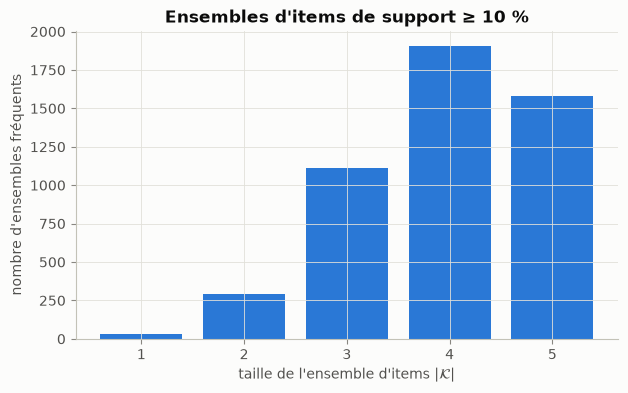

In [8]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(tailles.index, tailles.values, color=BLUE)
ax.set_xlabel("taille de l'ensemble d'items $|\\mathcal{K}|$")
ax.set_ylabel("nombre d'ensembles fréquents")
ax.set_title("Ensembles d'items de support ≥ 10 %")
plt.show()

Formons les règles. Nous gardons les règles à **conséquent unique** et de confiance au moins
80 % : on en obtient environ 6300, du même ordre que les 6288 règles rapportées par le livre
(les réglages exacts du logiciel utilisé par les auteurs ne sont pas précisés).

In [9]:
regles = ns.regles_association(frequents, confiance_min=0.0, noms=noms)
regles1 = regles[(regles.consequent.apply(len) == 1) & (regles.confiance >= 0.8)].copy()
print("Règles (toutes partitions, sans seuil de confiance) :", len(regles))
print("Règles à conséquent unique, confiance ≥ 0,8 :", len(regles1))

Règles (toutes partitions, sans seuil de confiance) : 81390
Règles à conséquent unique, confiance ≥ 0,8 : 6343


### 2.6 Figure 14.2 : fréquence des items dans les données et dans les règles

Le livre compare la fréquence relative de chaque indicatrice dans les données (proportion
des 1, normalisée pour sommer à 1) et parmi les items apparaissant dans les règles.

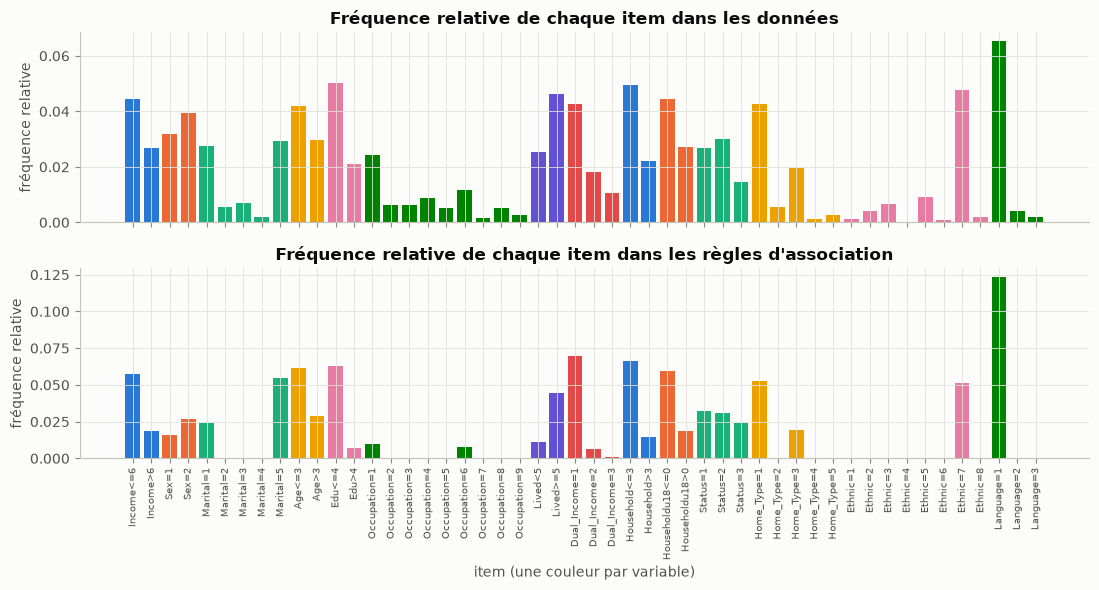

In [10]:
freq_donnees = Z.sum(0) / Z.sum()
compte = pd.Series(0.0, index=noms)
for A, B in zip(regles1.antecedent, regles1.consequent):
    for it in A + B:
        compte[it] += 1
freq_regles = compte / compte.sum()

fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
couleur_var = {v: COLORS[i % len(COLORS)] for i, v in enumerate(dict.fromkeys(variables))}
cols = [couleur_var[v] for v in variables]
axes[0].bar(range(50), freq_donnees, color=cols)
axes[0].set_ylabel("fréquence relative")
axes[0].set_title("Fréquence relative de chaque item dans les données")
axes[1].bar(range(50), freq_regles.values, color=cols)
axes[1].set_ylabel("fréquence relative")
axes[1].set_title("Fréquence relative de chaque item dans les règles d'association")
axes[1].set_xticks(range(50))
axes[1].set_xticklabels(noms, rotation=90, fontsize=7)
axes[1].set_xlabel("item (une couleur par variable)")
plt.tight_layout()
plt.show()

Comme dans le livre, les modalités **fréquentes** (langue anglaise, origine « blanc », foyer
de petite taille…) sont sur-représentées dans les règles, tandis que les modalités rares
(la plupart des professions, sauf « cadre » et quelques autres) en sont absentes : un item de
support inférieur à 10 % ne peut figurer dans aucune règle.

### 2.7 Interroger la base de règles

Le livre suggère de stocker les règles dans une base que l'on interroge. Écrivons une petite
fonction d'interrogation, qui traduit au passage les codes en libellés lisibles.

In [11]:
def libelle(item):
    """Traduit un item comme 'Status=1' en texte lisible."""
    for op in ("<=", ">=", "<", ">", "="):
        if op in item:
            v, val = item.split(op)
            break
    val = int(float(val))
    if op == "=" and v in ns.MODALITES_MARKETING:
        return "%s = %s" % (v, ns.MODALITES_MARKETING[v][val])
    return "%s %s %d" % (v, op, val)


def afficher(df, n=5):
    for _, r in df.head(n).iterrows():
        print("  SI   " + "  ET  ".join(libelle(a) for a in r.antecedent))
        print("  ALORS " + " ET ".join(libelle(b) for b in r.consequent))
        print("        support %.1f %%, confiance %.1f %%, lift %.2f\n"
              % (100 * r.support, 100 * r.confiance, r.lift))

**Règle de fort support menant à la langue anglaise** (analogue de la règle 1 du livre :
« foyer de petite taille, sans enfant ⇒ anglais à la maison »).

In [12]:
afficher(regles1[(regles1.consequent == ("Language=1",)) & (regles1.taille == 3)]
         .sort_values("support", ascending=False), n=2)

  SI   Household <= 3  ET  Householdu18 <= 0
  ALORS Language = anglais
        support 52.1 %, confiance 94.2 %, lift 1.03

  SI   Household <= 3  ET  Ethnic = blanc
  ALORS Language = anglais
        support 49.4 %, confiance 98.8 %, lift 1.08



Le lift est proche de 1 : 91 % des personnes interrogées parlent anglais à la maison, la règle
a donc une forte confiance « mécaniquement ».

**Règles menant à un revenu élevé** (analogue de la règle 2 du livre, utile pour cibler des
clients aisés).

In [13]:
afficher(regles1[regles1.consequent == ("Income>6",)].sort_values("confiance", ascending=False), n=3)

  SI   Marital = marié  ET  Occupation = cadre/profession libérale  ET  Status = propriétaire
  ALORS Income > 6
        support 10.4 %, confiance 87.5 %, lift 2.32

  SI   Marital = marié  ET  Occupation = cadre/profession libérale  ET  Home_Type = maison
  ALORS Income > 6
        support 10.4 %, confiance 84.1 %, lift 2.23

  SI   Marital = marié  ET  Dual_Income = oui  ET  Status = propriétaire  ET  Language = anglais
  ALORS Income > 6
        support 11.8 %, confiance 83.0 %, lift 2.20

